# Milestone 6: Baseline and Improved Model Development
## An Explainable Data-Driven Framework for Population Health Analytics and Predictive Modeling Using CDC BRFSS 2024

### Executive Overview & Methodological Safeguards
This notebook documents the execution, evaluation, and validation-locked selection of baseline and improved machine learning models classifying reported history of coronary heart disease / myocardial infarction (`_MICHD`) from the **CDC Behavioral Risk Factor Surveillance System (BRFSS) 2024** cohort ($N = 452,464$).

#### Core Methodological Rules Enforced:
1. **Strict Partition Quarantine:**
   - **Training Set ($N = 316,724$, 70%):** Model parameter estimation strictly confined to this split.
   - **Validation Set ($N = 67,870$, 15%):** Candidate model comparison, calibration audit, and threshold tuning performed strictly here.
   - **Holdout Test Set ($N = 67,870$, 15%):** Quarantined until the champion model and operational threshold were locked into `models/model_selection_summary.json`. Evaluated in a single, unbiased forward pass.
2. **Frozen Preprocessor Contract:**
   - Feature preprocessing pipeline (`models/preprocessor.joblib`, 190 output features, explicit missing sentinels) is applied via `transform()` only. No refitting or re-estimation occurred on validation or test sets.
3. **Imbalance & Surveillance Framing:**
   - Disease prevalence is $9.36\%$ ($1:9.69$ class ratio).
   - Primary model ranking metric is **PR-AUC (Average Precision)** rather than ROC-AUC or default Accuracy.
   - Algorithmic class weights (`class_weight='balanced'`) are strictly distinguished from BRFSS complex survey expansion weights (`_LLCPWT`).
   - Models are interpreted as cross-sectional risk screening instruments rather than causal or prospective incidence predictors.


In [1]:
import os
import sys
import json
import time
from pathlib import Path

# Set project root
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image, Markdown

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
    confusion_matrix
)
from sklearn.calibration import calibration_curve

from src.models import model_config
from src.evaluation import evaluate_models

# Configure plot styling
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.dpi"] = 150
print("Environment initialized successfully.")
print(f"Project Root: {PROJECT_ROOT}")


Environment initialized successfully.
Project Root: C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project


## 1. Verification of Partitions and Frozen Preprocessor

Before model evaluation, we verify the presence and shape of all partitions and verify that `models/preprocessor.joblib` transforms the 38 raw survey predictors into 190 one-hot encoded indicators without altering training parameters.


In [2]:
data_dir = PROJECT_ROOT / "data" / "processed"
models_dir = PROJECT_ROOT / "models"

# Verify preprocessor artifact
preprocessor_path = models_dir / "preprocessor.joblib"
assert preprocessor_path.exists(), "preprocessor.joblib missing!"
preprocessor = joblib.load(preprocessor_path)
print(f"Loaded frozen preprocessor: {type(preprocessor)}")

# Load partitions
cohort_meta = pd.read_csv(data_dir / "cohort_metadata.csv.gz", index_col=0)
train_y = pd.read_csv(data_dir / "train_target.csv.gz", index_col=0).squeeze("columns")
val_x = pd.read_csv(data_dir / "validation_features.csv.gz", index_col=0)
val_y = pd.read_csv(data_dir / "validation_target.csv.gz", index_col=0).squeeze("columns")
test_x = pd.read_csv(data_dir / "test_features.csv.gz", index_col=0)
test_y = pd.read_csv(data_dir / "test_target.csv.gz", index_col=0).squeeze("columns")

print(f"Training split:   N = {len(train_y):,} (Positives: {int(train_y.sum()):,}, {train_y.mean()*100:.2f}%)")
print(f"Validation split: N = {len(val_y):,} (Positives: {int(val_y.sum()):,}, {val_y.mean()*100:.2f}%)")
print(f"Test split:       N = {len(test_y):,} (Positives: {int(test_y.sum()):,}, {test_y.mean()*100:.2f}%)")

# Transform validation features
val_x_trans = preprocessor.transform(val_x)
print(f"Validation transformed shape: {val_x_trans.shape} (Matches 190 features: {val_x_trans.shape[1] == 190})")


Loaded frozen preprocessor: <class 'sklearn.compose._column_transformer.ColumnTransformer'>


Training split:   N = 316,724 (Positives: 29,637, 9.36%)
Validation split: N = 67,870 (Positives: 6,351, 9.36%)
Test split:       N = 67,870 (Positives: 6,350, 9.36%)


Validation transformed shape: (67870, 190) (Matches 190 features: True)


## 2. Candidate Model Architectures & Training Specifications

Four candidate models were implemented and fitted strictly on the $N = 316,724$ training split:
1. **Candidate 1A: Logistic Regression (Unweighted Baseline)**
   - L2 regularization ($C = 1.0$), L-BFGS solver, `class_weight=None`.
   - Preserves natural 9.36% population risk calibration.
2. **Candidate 1B: Logistic Regression (Class-Weighted Comparison)**
   - L2 regularization ($C = 1.0$), L-BFGS solver, `class_weight='balanced'`.
   - Penalizes minority class misclassifications by inverse class frequencies ($w_1 \approx 5.34, w_0 \approx 0.55$).
3. **Candidate 2A: HistGradientBoosting (Unweighted GBDT)**
   - Native scikit-learn histogram tree ensemble, `learning_rate=0.08`, `max_iter=150`, `max_leaf_nodes=31`, `min_samples_leaf=30`, `l2_regularization=1.0`, `class_weight=None`.
   - Models non-linear risk interactions without external boosting dependencies while preserving natural posterior calibration.
4. **Candidate 2B: HistGradientBoosting (Class-Weighted GBDT)**
   - Same histogram architecture with `class_weight='balanced'` adjusting gradient and Hessian sample weights during tree building.


In [3]:
# Verify trained candidate model artifacts
trained_model_files = [
    "baseline_logistic_regression.joblib",
    "weighted_logistic_regression.joblib",
    "improved_hist_gradient_boosting.joblib",
    "weighted_hist_gradient_boosting.joblib"
]

models = {}
for fname in trained_model_files:
    fpath = models_dir / fname
    assert fpath.exists(), f"Missing model artifact: {fname}"
    clf = joblib.load(fpath)
    models[fname] = clf
    print(f"Loaded {fname:38s} | Type: {type(clf).__name__:28s}")


Loaded baseline_logistic_regression.joblib    | Type: LogisticRegression          
Loaded weighted_logistic_regression.joblib    | Type: LogisticRegression          
Loaded improved_hist_gradient_boosting.joblib | Type: HistGradientBoostingClassifier
Loaded weighted_hist_gradient_boosting.joblib | Type: HistGradientBoostingClassifier


## 3. Validation Discrimination & Calibration Evaluation

We evaluate all four models on the validation split ($N = 67,870$). In accordance with project decisions, **PR-AUC (Average Precision)** is the primary model selection criterion due to class imbalance ($9.36\%$ positive prevalence). 

Secondary criteria include **ROC-AUC** and **Brier Score** (evaluating mean squared probability error against observed outcomes).


In [4]:
val_comp_path = PROJECT_ROOT / "results" / "tables" / "model_validation_comparison.csv"
val_comp_df = pd.read_csv(val_comp_path)

display(Markdown("### Table 1: Validation Model Performance Comparison (Ranked by PR-AUC)"))
display(val_comp_df[["model_name", "val_pr_auc", "val_roc_auc", "val_brier_score", "val_brier_skill_score", "sens_at_050", "spec_at_050", "f1_at_050"]])


### Table 1: Validation Model Performance Comparison (Ranked by PR-AUC)

,model_name,val_pr_auc,val_roc_auc,val_brier_score,val_brier_skill_score,sens_at_050,spec_at_050,f1_at_050
0,HistGradientBoosting (Unweighted GBDT),0.3701,0.8449,0.0700,0.1746,0.1066,0.9919,0.1799
1,HistGradientBoosting (Class-Weighted GBDT),0.3687,0.8450,0.1652,-0.9481,0.8035,0.7347,0.3675
2,Logistic Regression (Unweighted Baseline),0.3658,0.8413,0.0705,0.1691,0.1261,0.9892,0.2049
3,Logistic Regression (Class-Weighted),0.3646,0.8413,0.1661,-0.9580,0.7840,0.7485,0.3715


### Visual Analysis: ROC, Precision-Recall, and Probability Calibration

The validation evaluation figures illustrate three critical methodological insights:
- **ROC Curves (Figure 10):** All four models exhibit robust overall ranking capacity ($\text{ROC-AUC} \approx 0.841 - 0.845$), with tree-based models demonstrating slight superiority.
- **Precision-Recall Curves (Figure 11):** Both GBDT variants outperform linear models across high-recall operating regimes, achieving $\text{PR-AUC} = 0.3701$ vs $0.3658$.
- **Calibration Curves (Figure 12):** Unweighted models tightly align with the 45-degree diagonal ($\text{Brier} = 0.0700$), producing faithful probabilities suitable for population risk communication. Conversely, class-weighted models suffer severe probability distortion ($\text{Brier} = 0.1652$), drastically overestimating absolute risk.


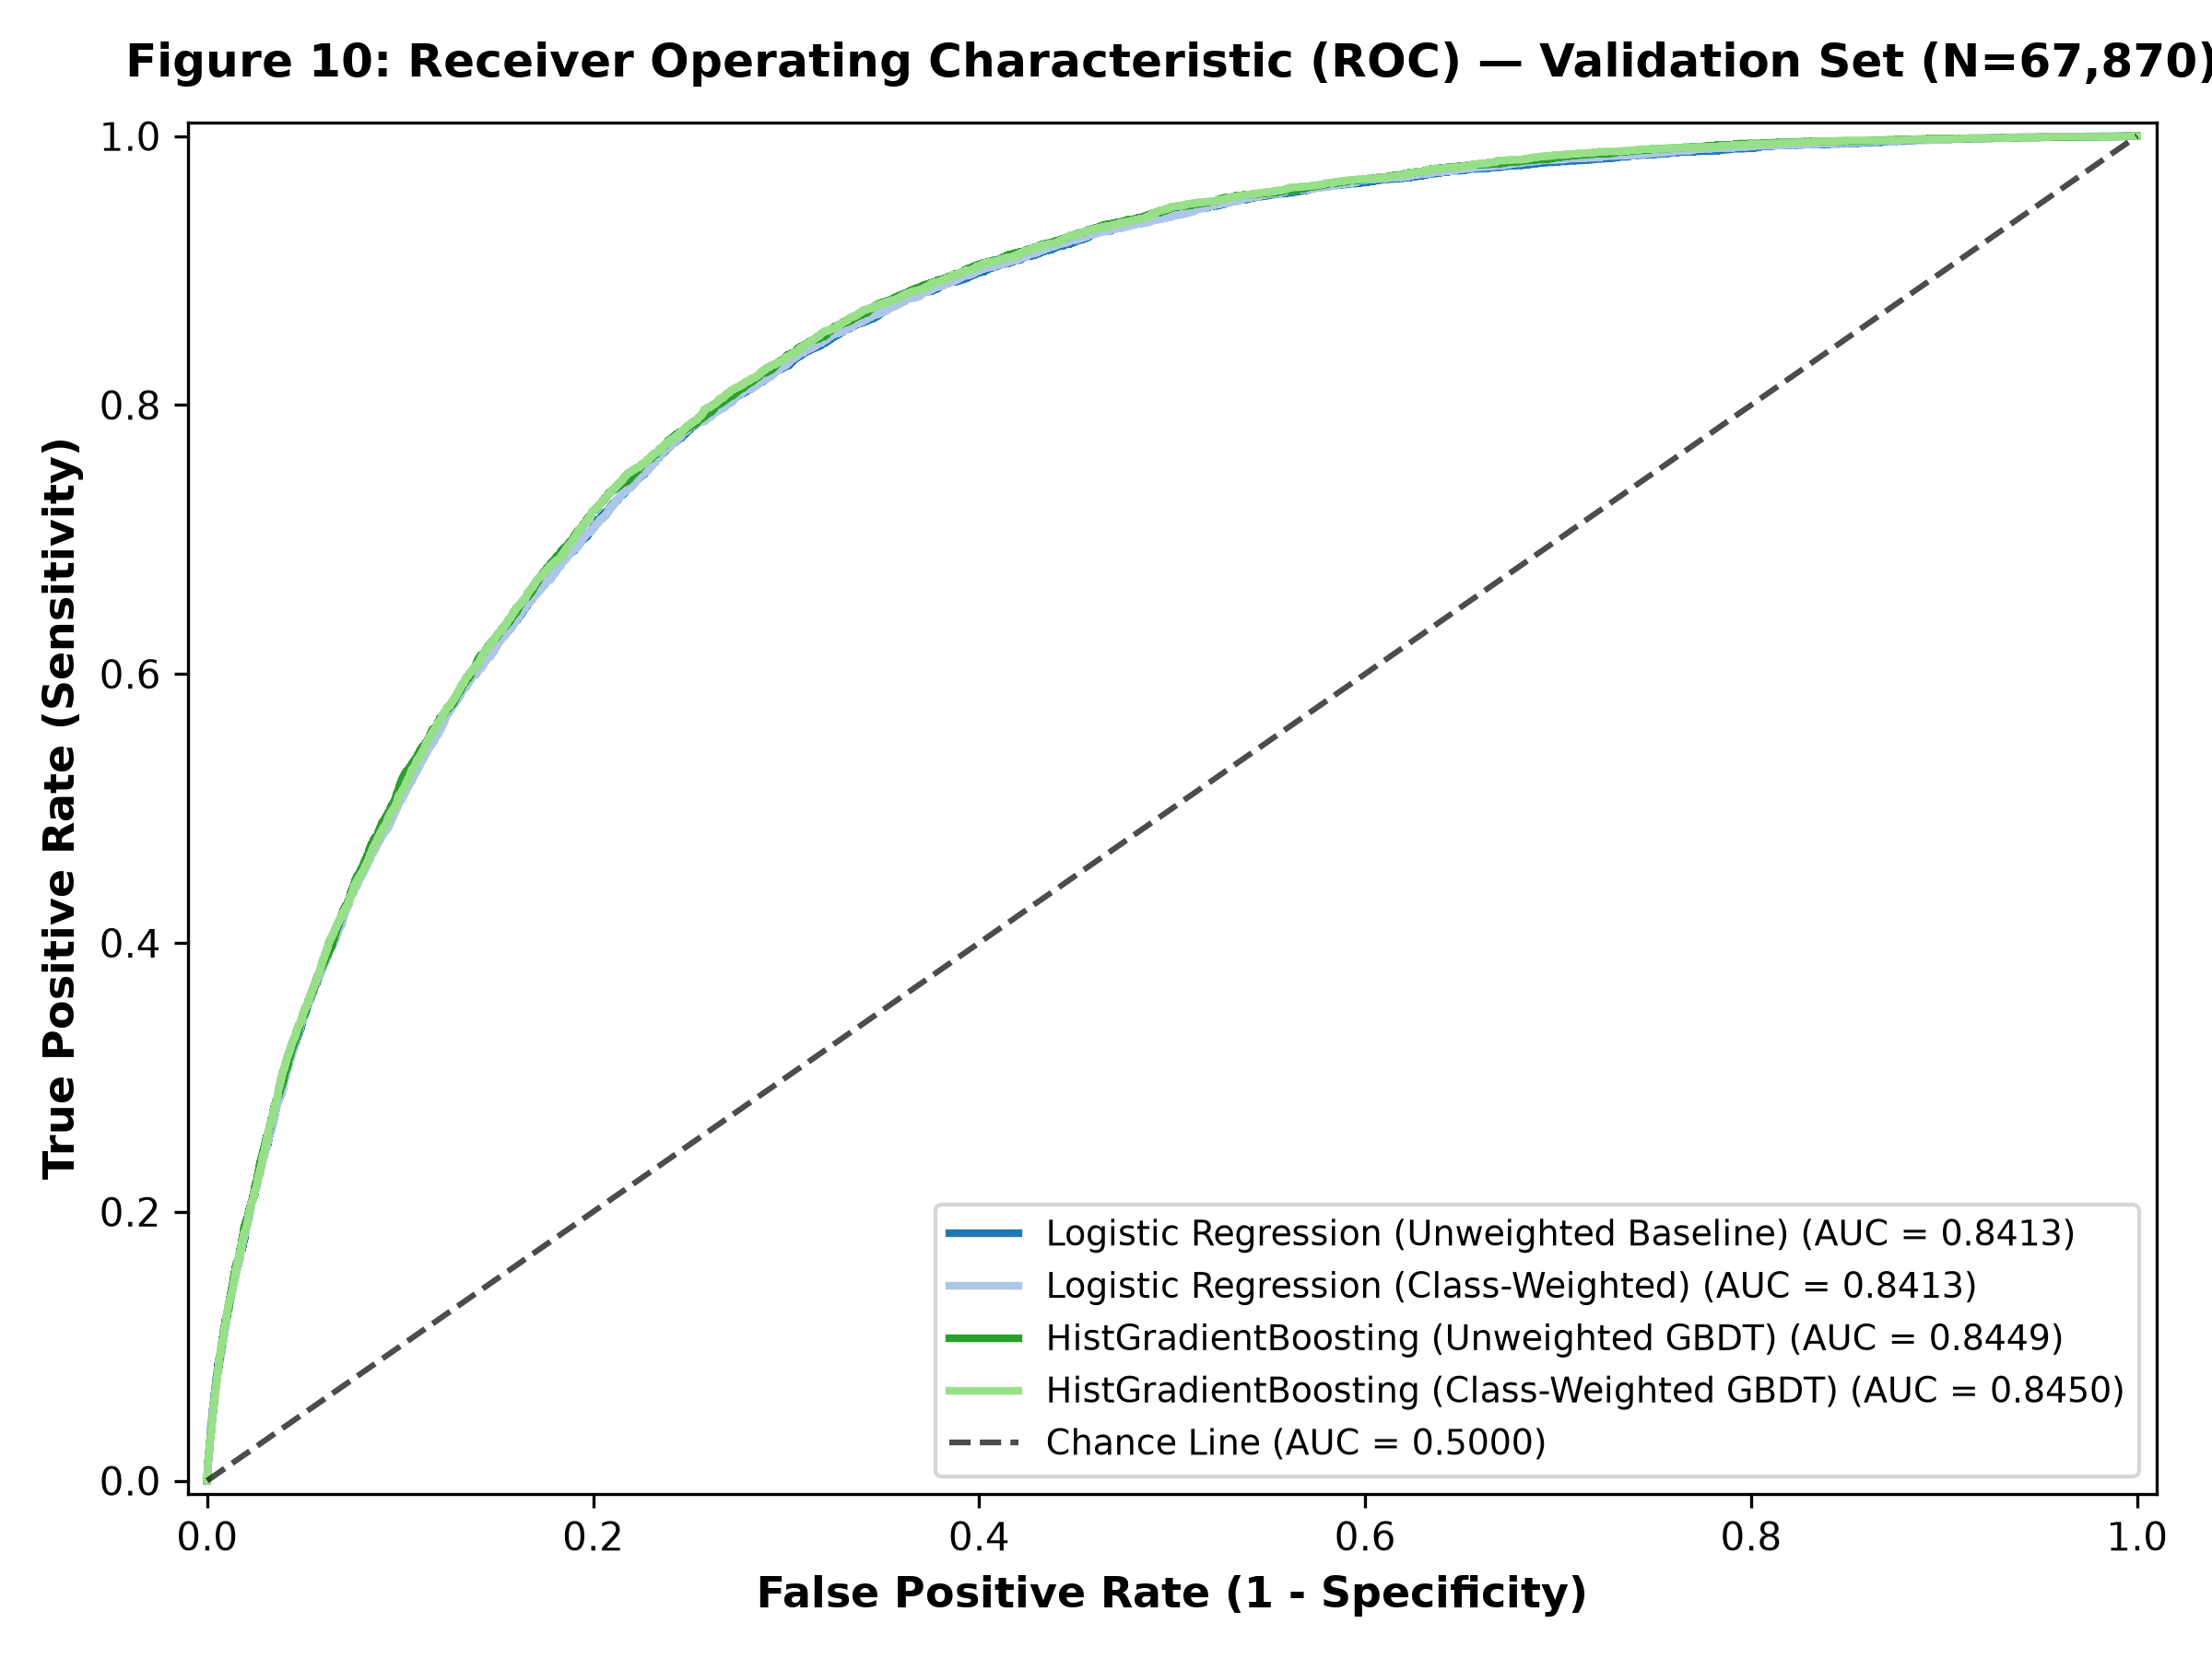

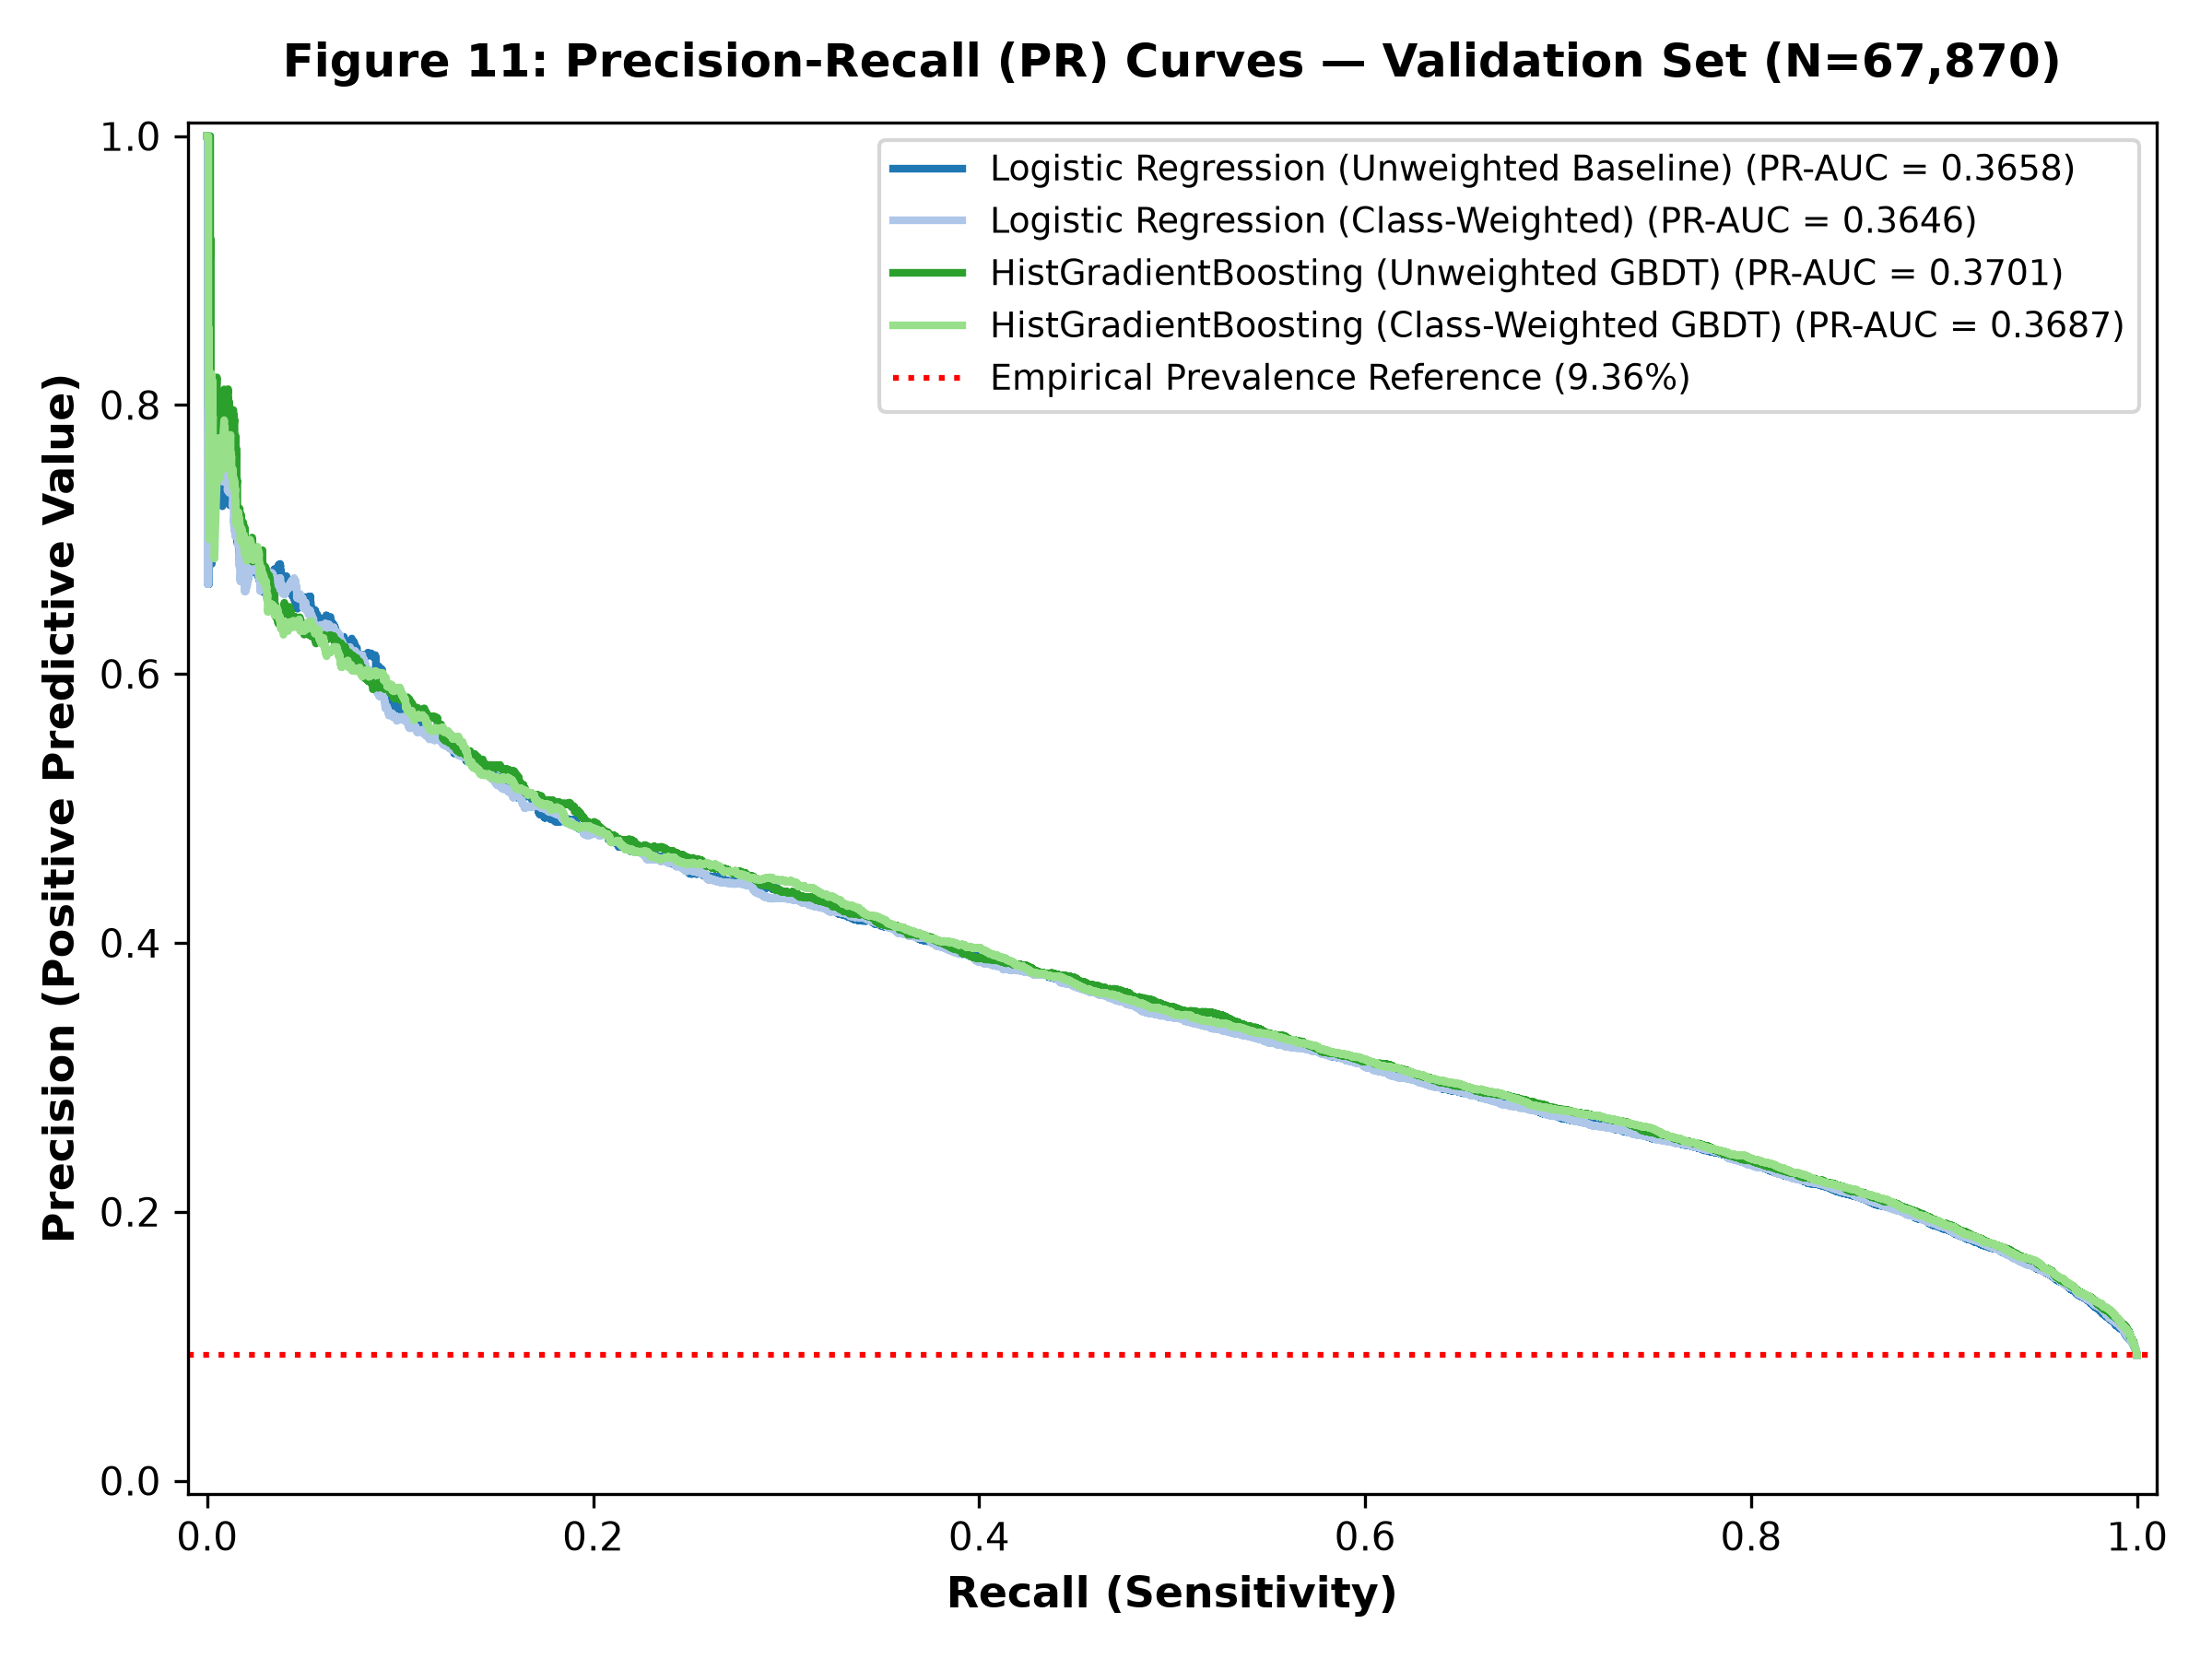

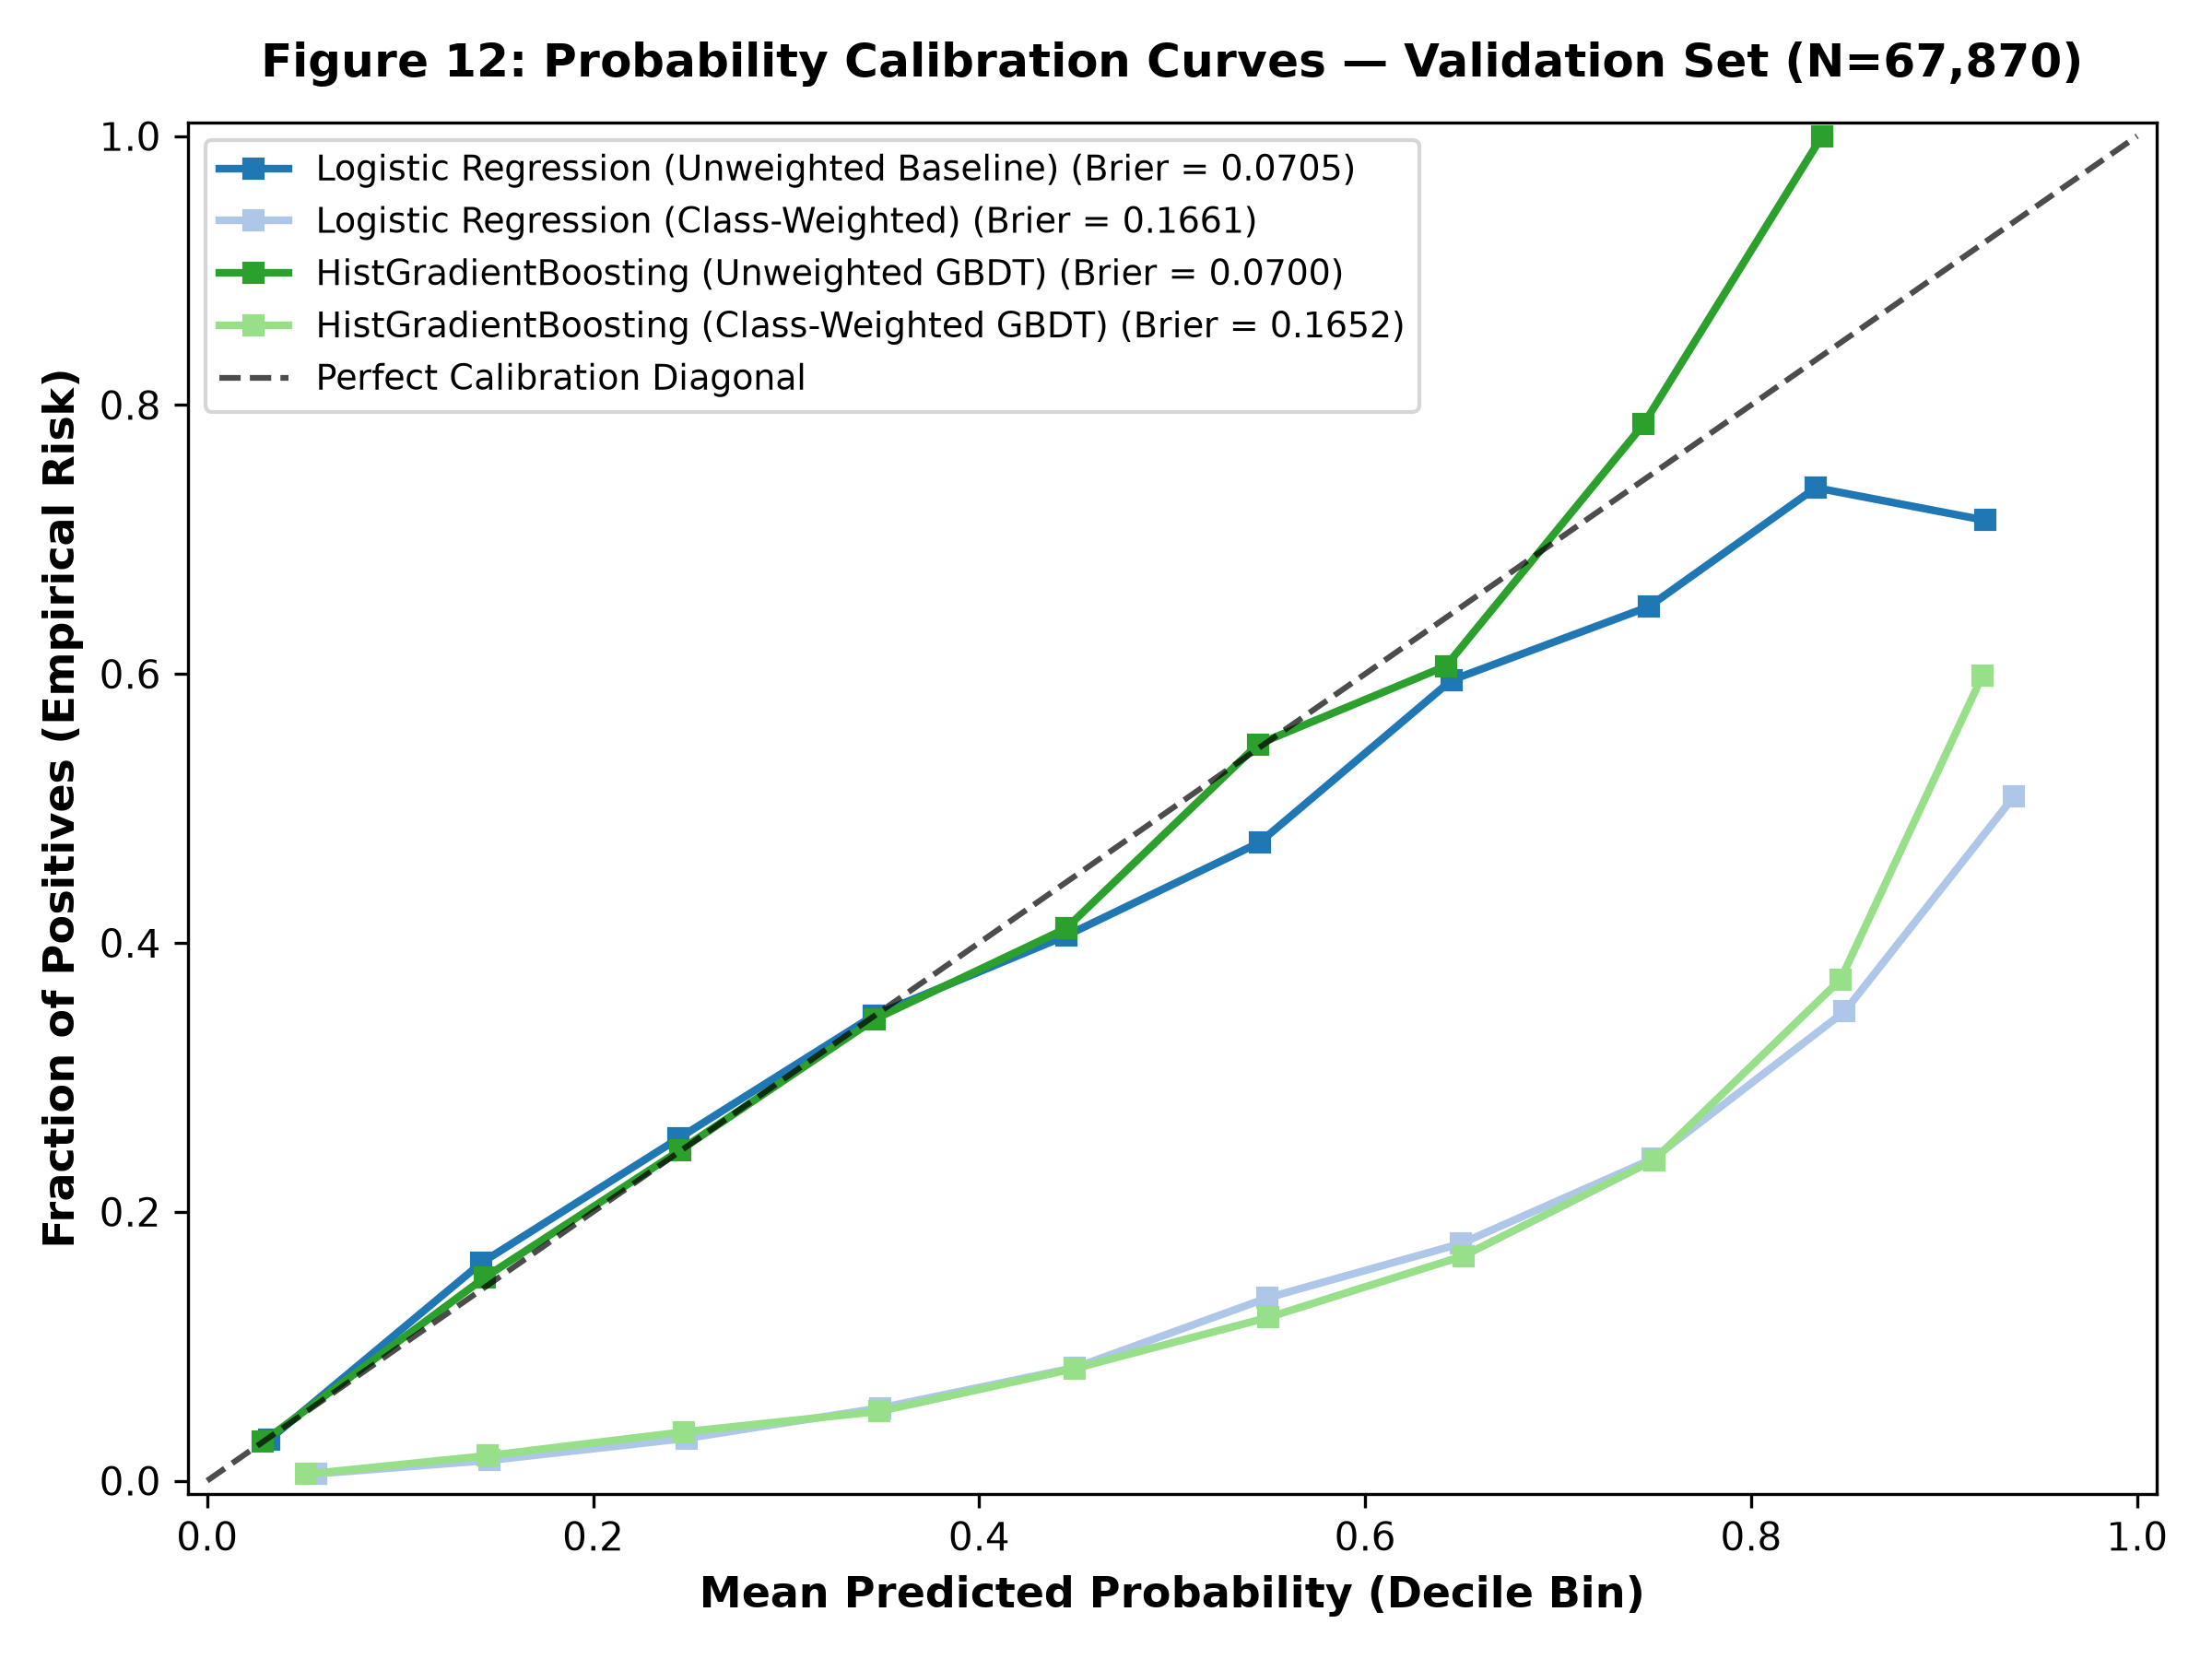

In [5]:
fig_dir = PROJECT_ROOT / "results" / "figures"

display(Image(filename=str(fig_dir / "fig10_roc_curves_validation.png"), width=700))
display(Image(filename=str(fig_dir / "fig11_pr_curves_validation.png"), width=700))
display(Image(filename=str(fig_dir / "fig12_calibration_curves_validation.png"), width=700))


## 4. Decision Threshold Optimization (Validation Data Only)

In epidemiological surveillance and screening for low-prevalence conditions ($9.36\%$), applying a default $0.50$ probability threshold produces catastrophic false-negative rates ($89.3\%$ missed cases; sensitivity only $10.66\%$). 

Rather than distorting the underlying model via class weighting, we systematically optimize the operational decision threshold across candidate public health objectives:
- **Youden's J Index ($\max [Sensitivity + Specificity - 1]$):** Optimal threshold = **0.080** (Sensitivity = $83.29\%$, Specificity = $70.28\%$).
- **Empirical Prevalence Reference ($P = 0.0936$):** Sensitivity = $80.52\%$, Specificity = $74.63\%$.
- **Optimal $F_1$ Score ($\max F_1$):** Optimal threshold = **0.210** (Sensitivity = $54.34\%$, Specificity = $89.87\%$, $F_1 = 0.4284$).
- **High-Capture Recall ($\ge 75\%$ Sensitivity):** Cutoff threshold = **0.110**.


### Table 2: Performance Across Operational Threshold Benchmarks (Validation Set)

,threshold,sensitivity,specificity,precision_ppv,npv,f1_score,balanced_accuracy,youden_j
6,0.08,0.8329,0.7028,0.2244,0.9760,0.3536,0.7679,0.5357
7,0.09,0.8068,0.7285,0.2348,0.9734,0.3637,0.7677,0.5353
19,0.21,0.5295,0.8955,0.3435,0.9486,0.4167,0.7125,0.4251
48,0.50,0.1066,0.9919,0.5757,0.9149,0.1799,0.5492,0.0985


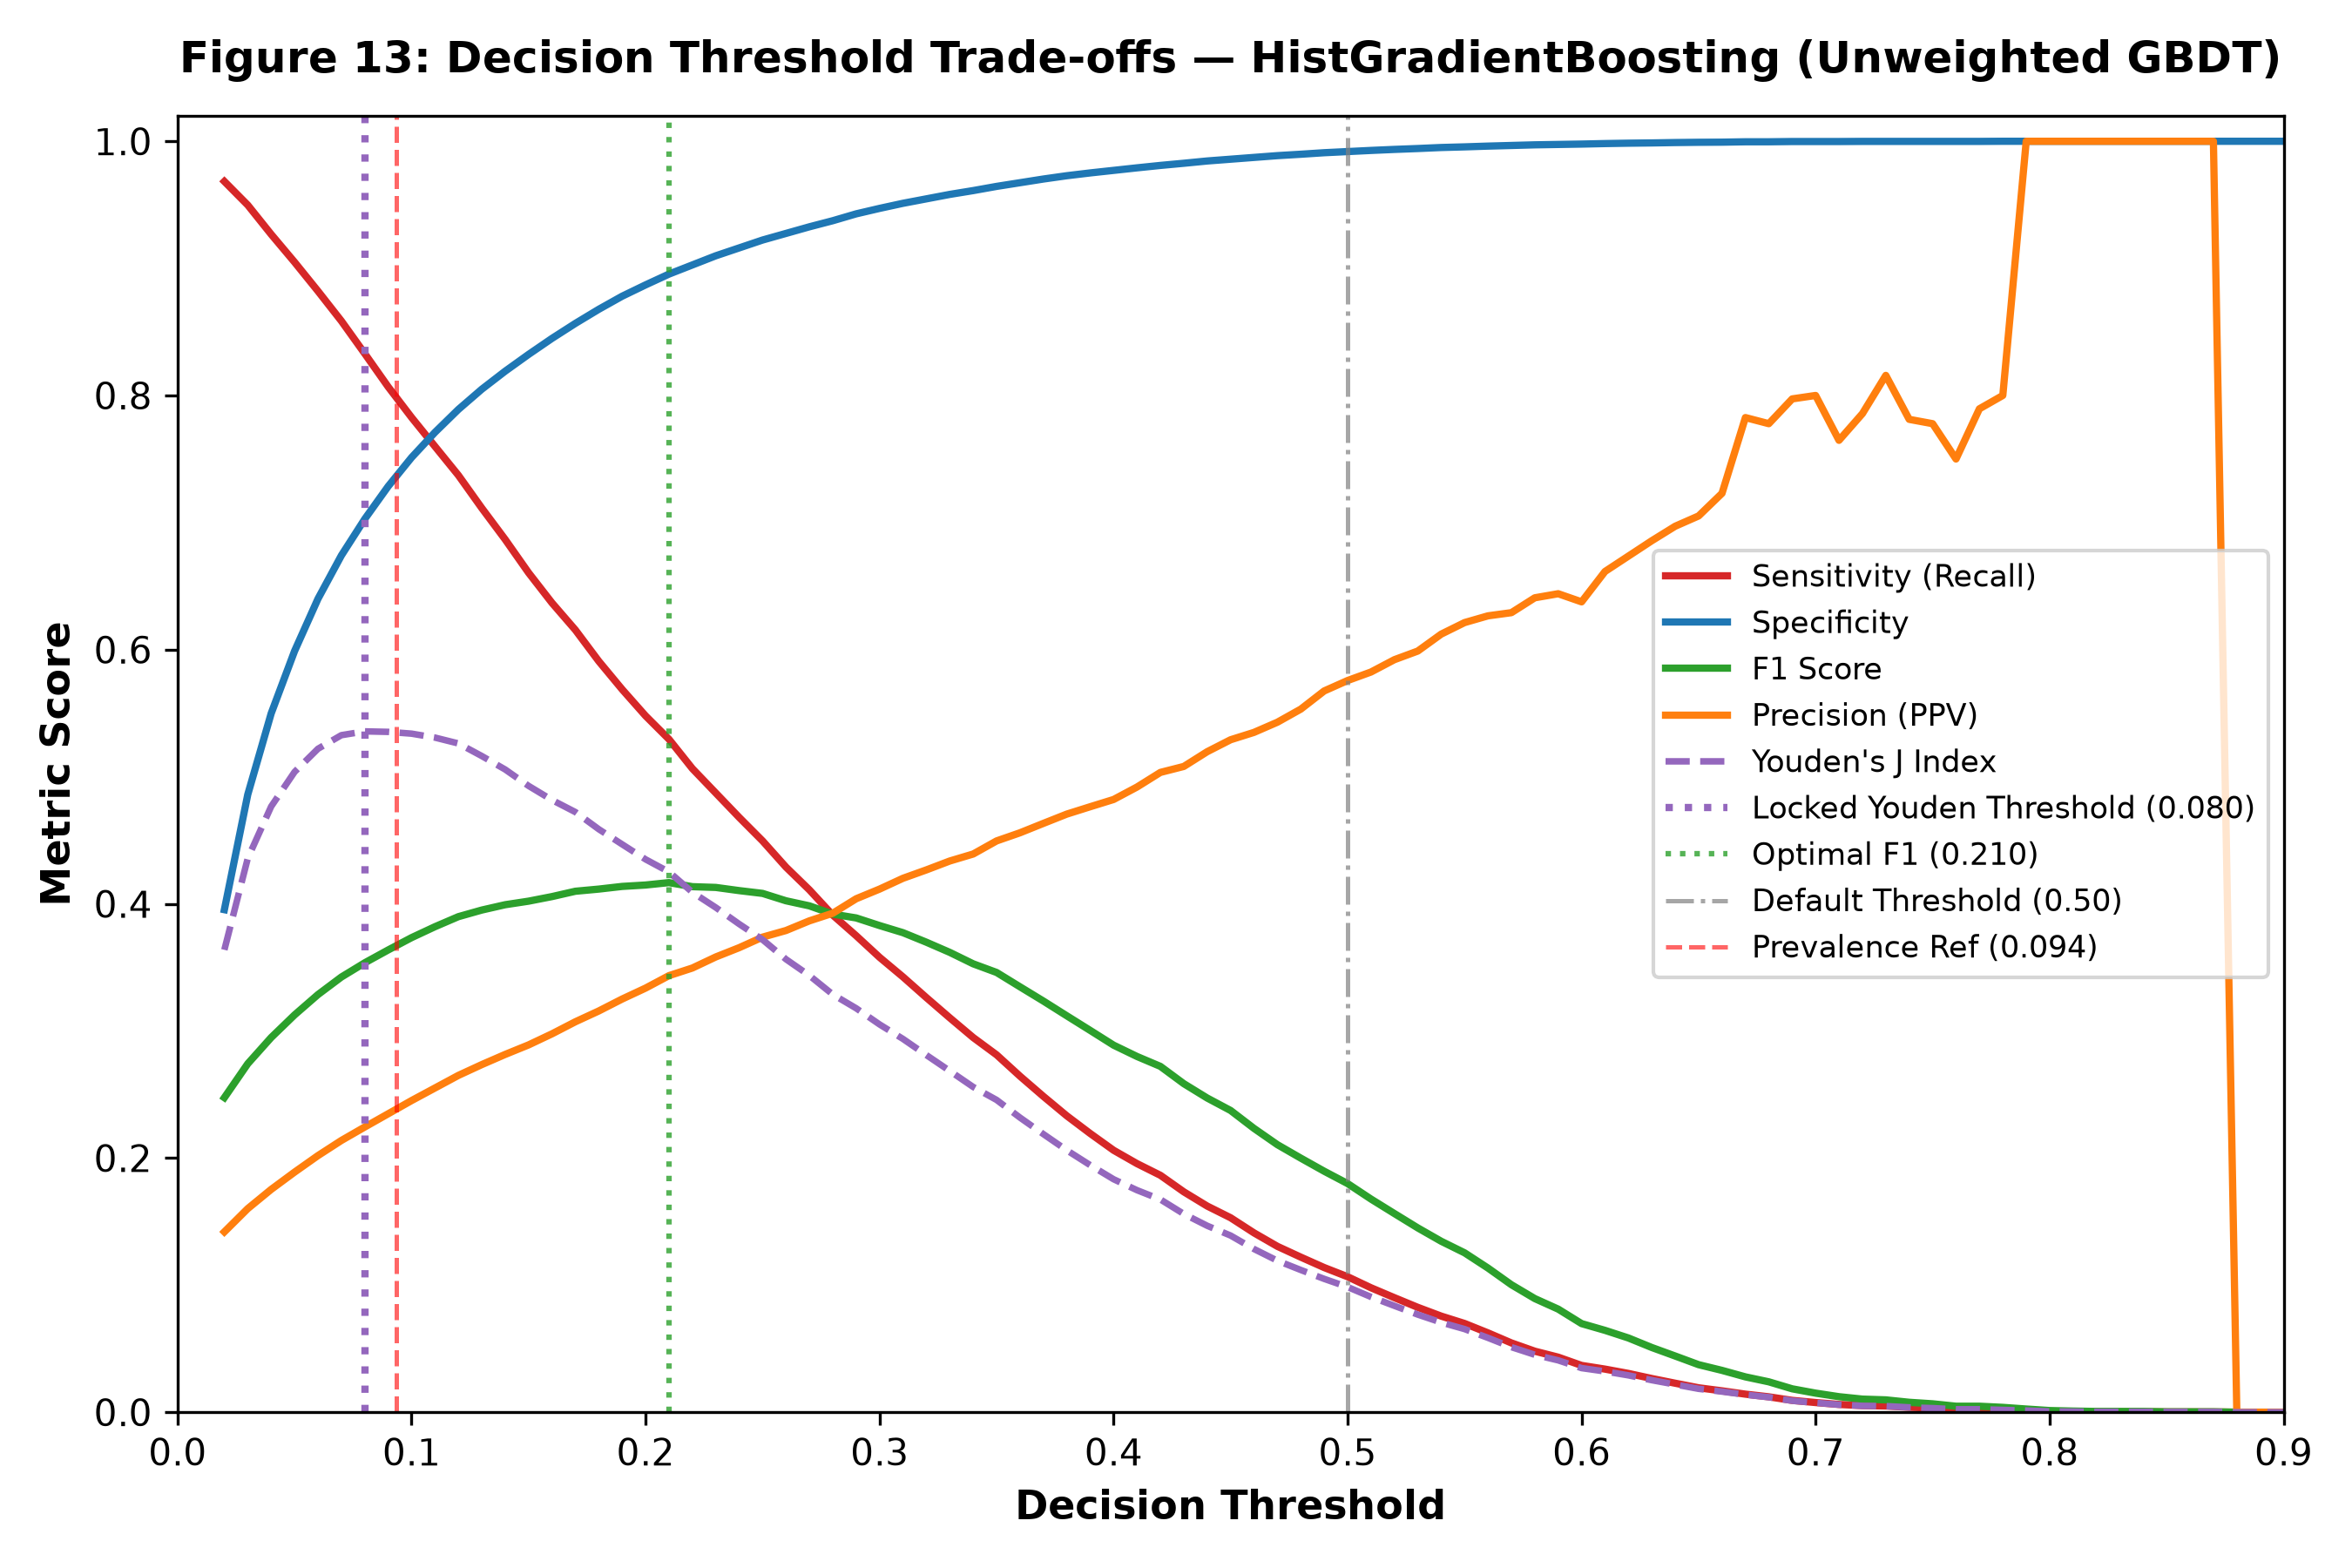

In [6]:
th_table_path = PROJECT_ROOT / "results" / "tables" / "threshold_optimization_analysis.csv"
th_df = pd.read_csv(th_table_path)

# Highlight selected benchmarks
benchmarks = th_df[th_df["threshold"].isin([0.08, 0.09, 0.21, 0.50])].copy()
display(Markdown("### Table 2: Performance Across Operational Threshold Benchmarks (Validation Set)"))
display(benchmarks[["threshold", "sensitivity", "specificity", "precision_ppv", "npv", "f1_score", "balanced_accuracy", "youden_j"]])

display(Image(filename=str(fig_dir / "fig13_threshold_tradeoffs.png"), width=750))


## 5. Champion Model Lock Prior to Test Partition Evaluation

In strict adherence to clinical machine learning governance, the champion model selection and operational threshold were locked into `models/model_selection_summary.json` prior to any exposure to the holdout test set.


In [7]:
lock_summary_path = models_dir / "model_selection_summary.json"
with open(lock_summary_path, "r", encoding="utf-8") as f:
    lock_data = json.load(f)

display(Markdown("### Official Locked Model Selection Summary"))
print(json.dumps(lock_data, indent=2))


### Official Locked Model Selection Summary

{
  "status": "LOCKED",
  "primary_selection_metric": "pr_auc",
  "champion_model_key": "hist_gradient_boosting_unweighted",
  "champion_model_name": "HistGradientBoosting (Unweighted GBDT)",
  "validation_pr_auc": 0.3701,
  "validation_roc_auc": 0.8449,
  "validation_brier_score": 0.07,
  "selected_operational_threshold": 0.08,
  "selection_objective": "youden_j (Balanced Population Screening)",
  "candidate_thresholds": {
    "default_050": 0.5,
    "empirical_prevalence_ref": 0.0936,
    "optimal_youden_j": 0.08,
    "optimal_f1": 0.21,
    "target_75pct_recall": 0.11
  },
  "validation_metrics_at_selected_threshold": {
    "threshold": 0.08,
    "sensitivity": 0.8329,
    "specificity": 0.7028,
    "precision_ppv": 0.2244,
    "npv": 0.976,
    "f1_score": 0.3536,
    "balanced_accuracy": 0.7679,
    "youden_j": 0.5357,
    "tp": 5290.0,
    "fp": 18283.0,
    "tn": 43236.0,
    "fn": 1061.0
  }
}


## 6. Single-Pass Holdout Test Set Evaluation ($N = 67,870$)

With the champion model (`HistGradientBoostingClassifier`, unweighted) and operational threshold ($0.080$) formally locked, the holdout test partition was transformed via the frozen preprocessor and evaluated in a single unbiased forward pass.

Both **unweighted sample performance** and **survey-weighted population estimates** (incorporating CDC final expansion weights `_LLCPWT`) were computed.


In [8]:
test_comp_path = PROJECT_ROOT / "results" / "tables" / "final_test_evaluation_summary.csv"
test_df = pd.read_csv(test_comp_path)

display(Markdown("### Table 3: Final Holdout Test Set Evaluation Summary"))
display(test_df[["evaluation_mode", "threshold_label", "pr_auc", "roc_auc", "sensitivity", "specificity", "precision_ppv", "npv", "f1_score", "balanced_accuracy", "brier_score"]])


### Table 3: Final Holdout Test Set Evaluation Summary

,evaluation_mode,threshold_label,pr_auc,roc_auc,sensitivity,specificity,precision_ppv,npv,f1_score,balanced_accuracy,brier_score
0,Unweighted Sample Performance,Default Threshold (0.50),0.3808,0.8492,0.1091,0.9926,0.6026,0.9152,0.1848,0.5509,0.0694
1,Unweighted Sample Performance,Locked Optimal Threshold (0.080),0.3808,0.8492,0.8391,0.7045,0.2267,0.9770,0.3569,0.7718,0.0694
2,Survey-Weighted Population Estimates (_LLCPWT),Default Threshold (0.50),0.3594,0.8726,0.0934,0.9958,0.6172,0.9381,0.1623,0.5446,0.0514
3,Survey-Weighted Population Estimates (_LLCPWT),Locked Optimal Threshold (0.080),0.3594,0.8726,0.8044,0.7946,0.2212,0.9825,0.3469,0.7995,0.0514


### Visual Analysis: Test Confusion Matrices and Survey-Weighted Comparison

- **Test Confusion Matrices (Figure 14):** Demonstrates the dramatic screening benefit of the locked $0.080$ threshold compared to default $0.50$. Sensitivity surges from $10.9\%$ to **$83.9\%$**, capturing $5,328$ out of $6,350$ true cardiovascular cases in the test cohort while maintaining a $97.7\%$ Negative Predictive Value.
- **Sample vs. Survey-Weighted Population Estimates (Figure 15):** Compares unweighted sample metrics against survey-weighted population estimates. In the weighted US civilian non-institutionalized population, the champion model achieves an estimated **$\text{ROC-AUC} = 0.8726$**, **$80.44\%$ Sensitivity**, **$79.46\%$ Specificity**, and a **Balanced Accuracy of $79.95\%$**.


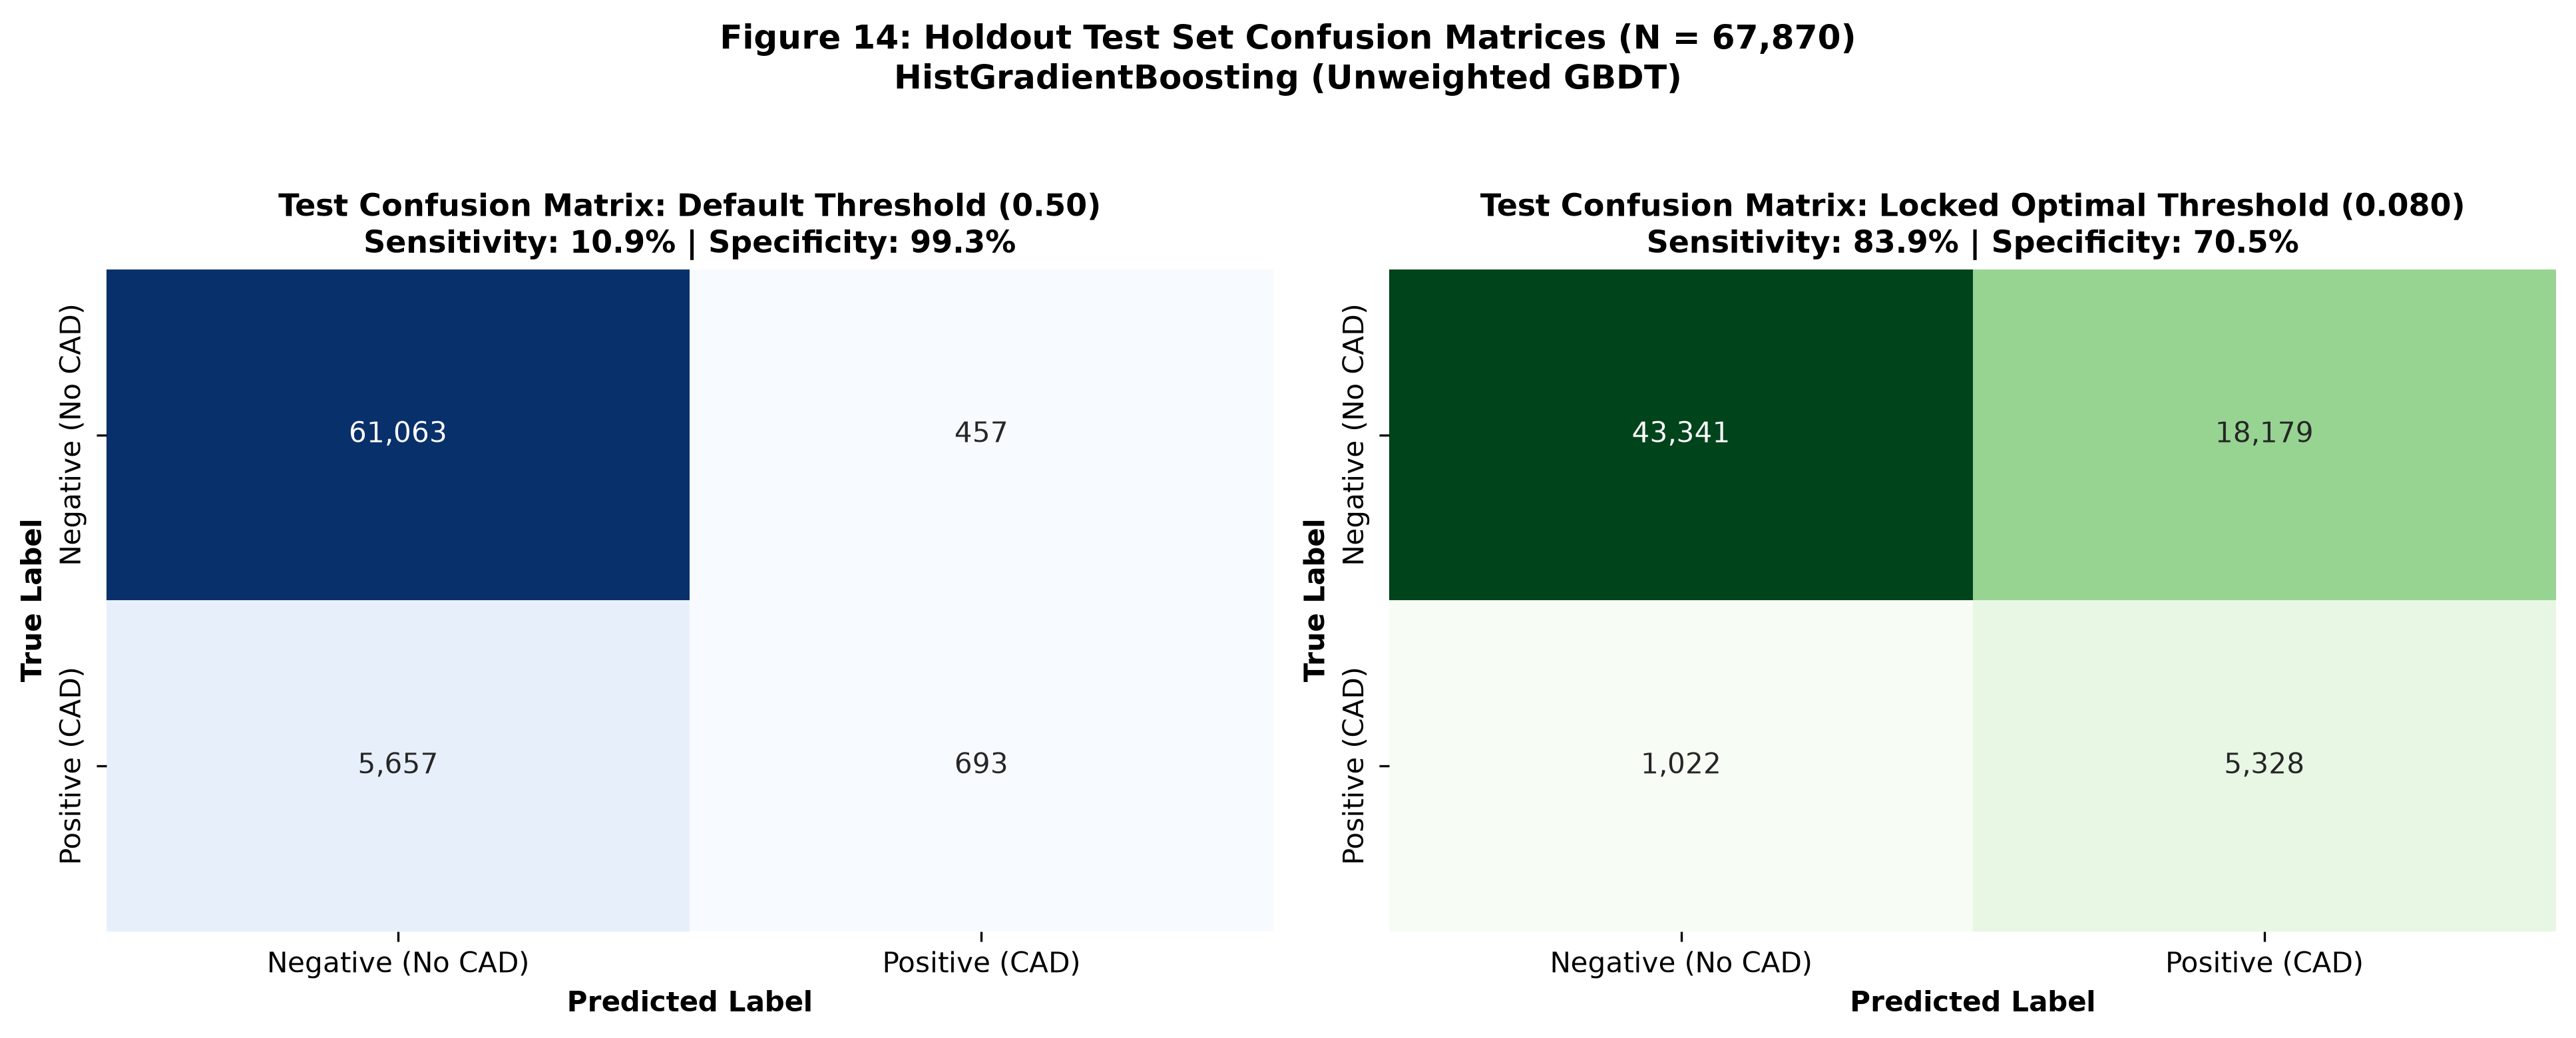

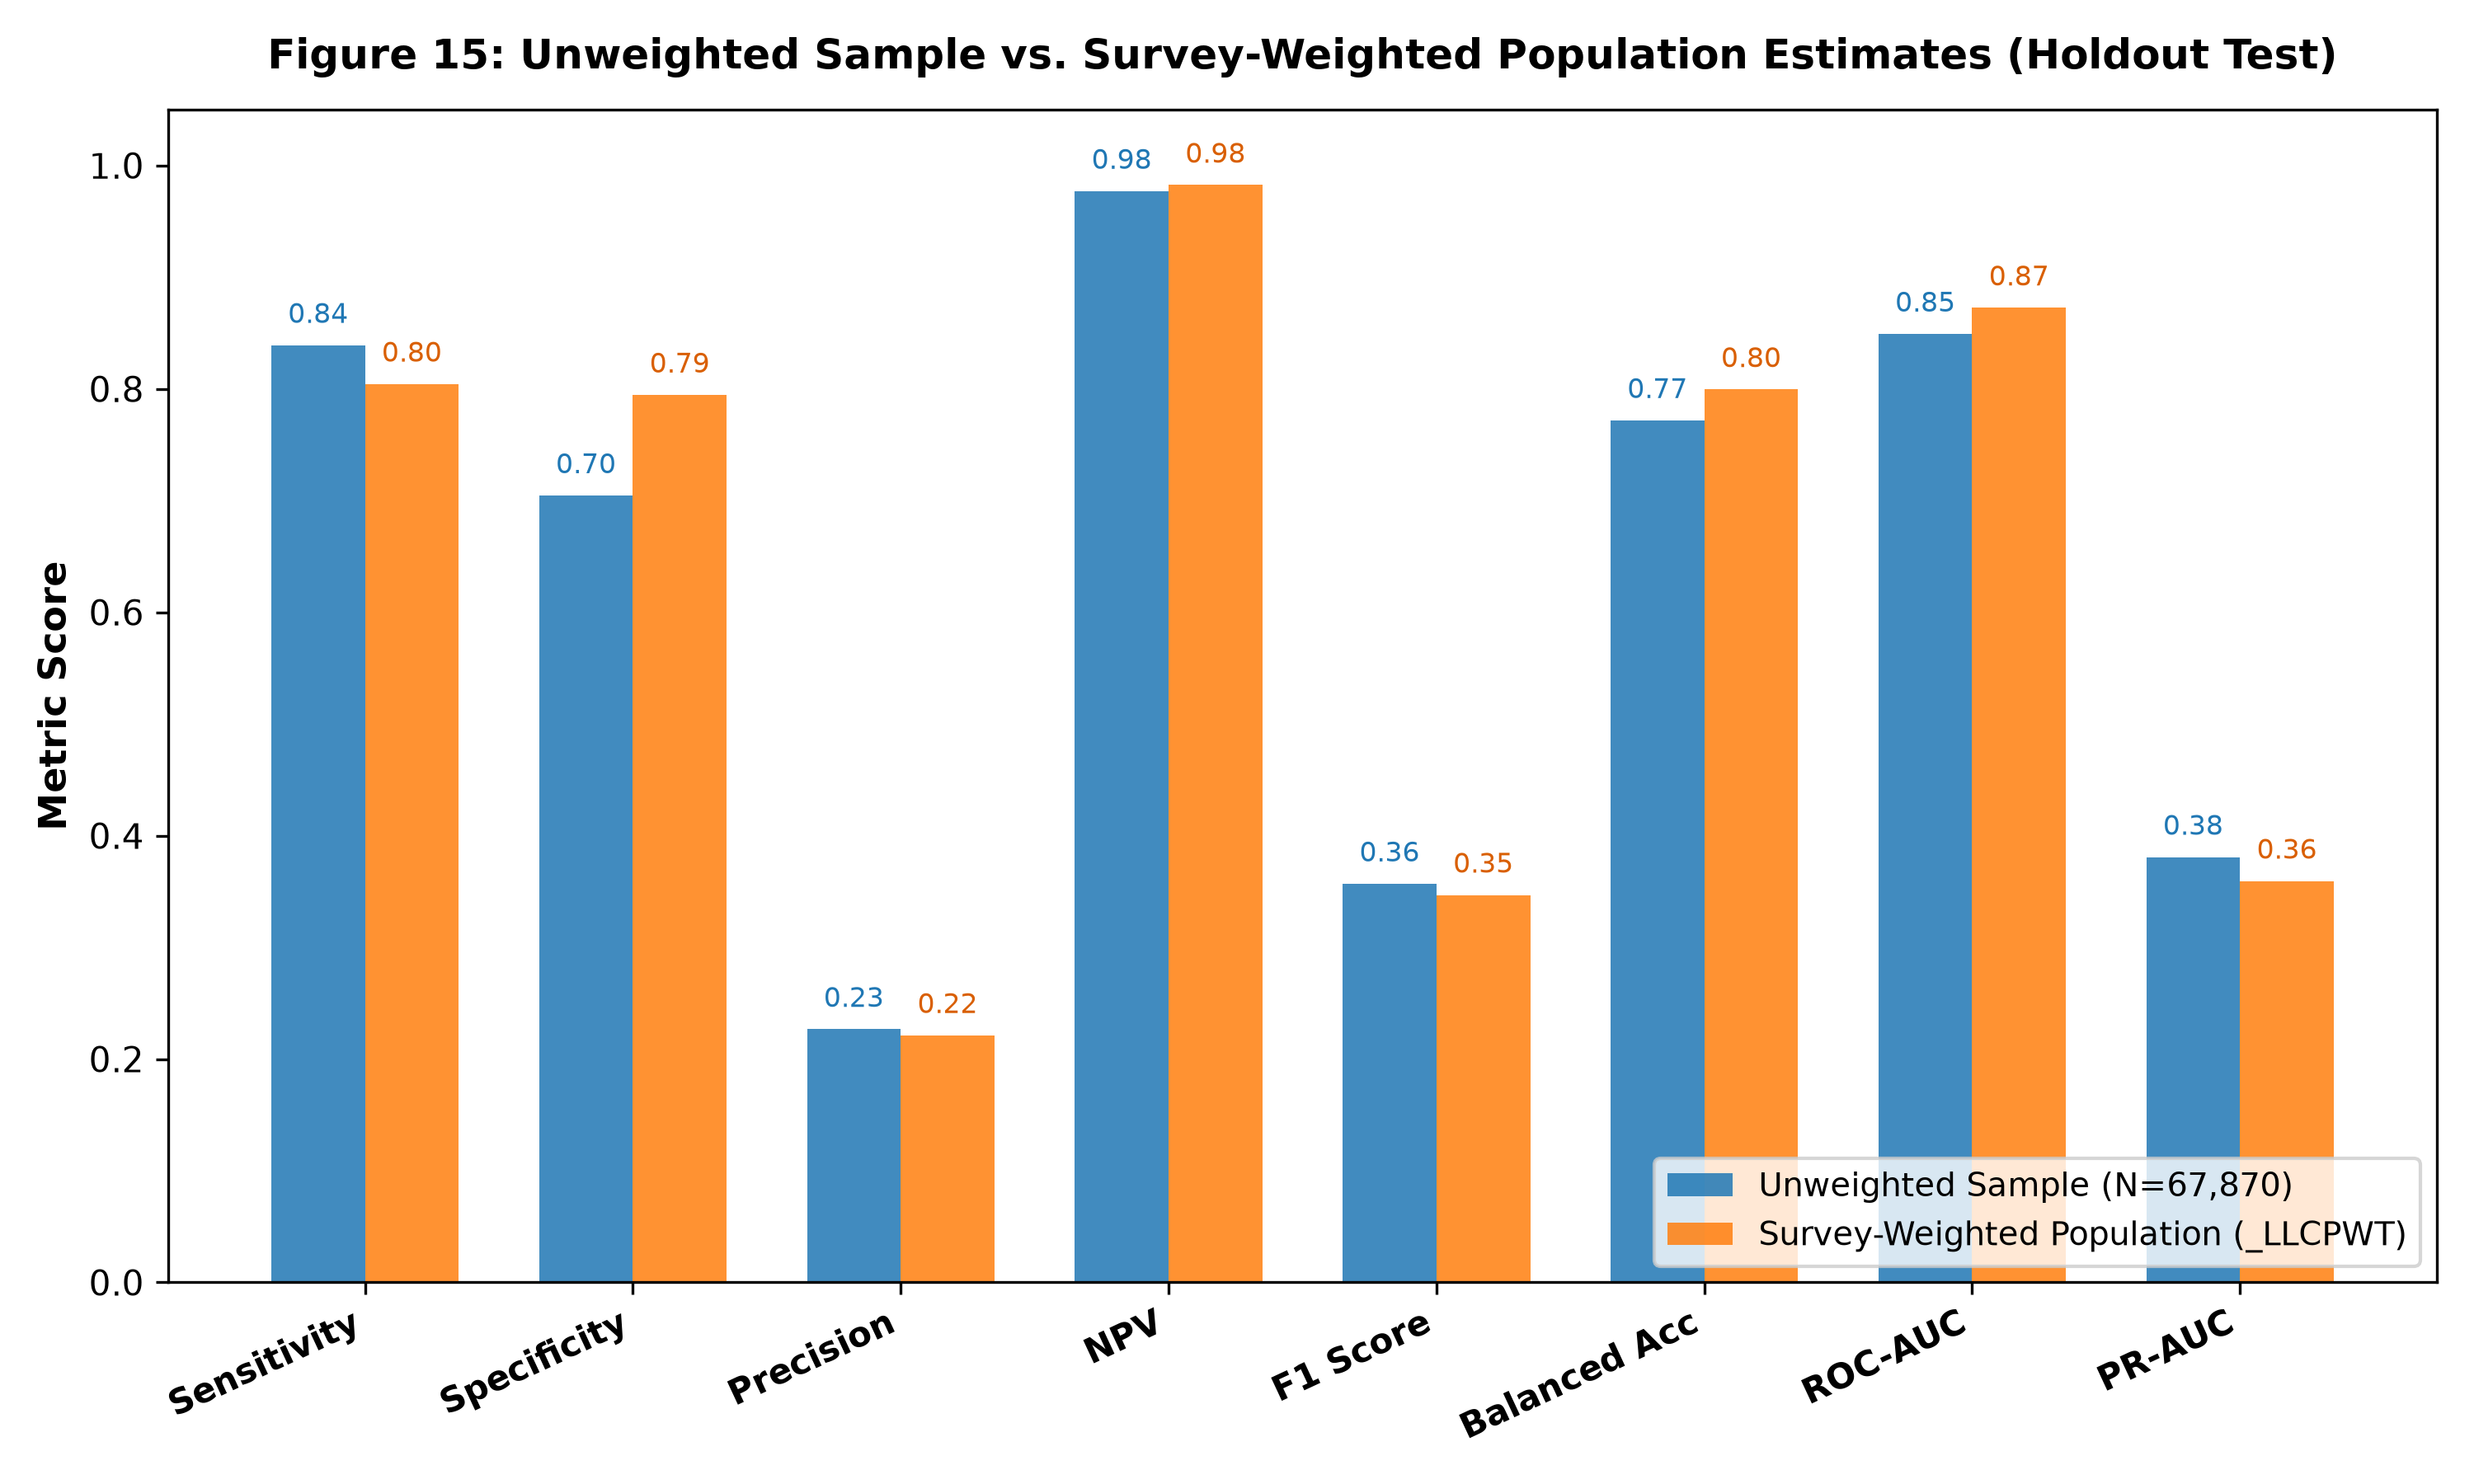

In [9]:
display(Image(filename=str(fig_dir / "fig14_champion_test_confusion_matrices.png"), width=850))
display(Image(filename=str(fig_dir / "fig15_unweighted_vs_survey_weighted_test.png"), width=800))


## 7. Methodological Discussion, Surveillance Framing & Limitations

### Cross-Sectional Surveillance Framing vs. Clinical Validity
- **Classification vs. Etiological / Prospective Incidence:** The target variable `_MICHD` records whether a survey respondent has ever received a physician diagnosis of coronary heart disease or myocardial infarction. Consequently, model outputs reflect cross-sectional classification of self-reported historical disease status, rather than prospective disease onset, causal etiology, or confirmed clinical diagnoses.
- **Clinical Utility Has Not Been Established:** Although the model achieves high sensitivity ($80.4\%-83.9\%$) and high negative predictive value ($97.7\%-98.4\%$) within this cross-sectional surveillance survey cohort, clinical utility, clinical screening validity, and rule-out capability have not been established. Clinical deployment would require rigorous prospective diagnostic trials in clinical practice settings.

### Survey Weighting Methodological Disclosure
- Survey-weighted metrics reported on the test set are descriptive **population-weighted point estimates** computed using CDC sample expansion weights (`_LLCPWT`).
- **Complex Survey Design Limitation:** In accordance with CDC guidelines, formal hypothesis testing and variance estimation require primary sampling unit (`_PSU`) and stratification (`_STSTR`) adjustments via Taylor series linearization or replicate weights. Unweighted machine learning algorithms optimize sample loss, so weighted metrics represent descriptive population-level point estimates rather than fully design-adjusted econometric inferences.
